# Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0" # whatever is free
# os.environ["JAX_PLATFORM_NAME"] = "cpu"
# os.environ["JAX_LOG_COMPILES"] = "1" # to see jit compiliation triggers

from loguru import logger
import jax
logger.info(f'JAX is using: {jax.devices()}')

2026-06-04 18:21:12.484 | INFO     | __main__:<module>:8 - JAX is using: [CudaDevice(id=0)]


In [ ]:
from pathlib import Path
from datetime import datetime
import wandb

from tqdm.auto import tqdm
import numpy as np
import jax.random as jr
import jax.numpy as jnp

from apa.utils.config import load_config
from apa.utils.env import load_levels, get_random_envs, make_env_from_config, duplicate_env_states
from apa.repo import RandomMatchingRepo, ConstantMatchingRepo, PixelMatchingRepo, EvalRepo, MorphologyMatchingRepo, PerformanceMatchingRepo, DinoMatchingRepo

In [4]:
config_folder = Path('../third_party/kinetix/configs')
assert config_folder.exists()
config = load_config(config_path=str(config_folder),config_name='naive_repo')

rng = jax.random.PRNGKey(config.get('seed',0))

In [5]:
USE_WANDB = config['use_wandb']

run_folder_name = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

if USE_WANDB:
    wandb_run = wandb.init(
        project="Naive Skill Repo", 
        config=dict(config),
        name = config.get('wandb_runname', None)
    )

    wandb.define_metric("repo_step")
    # wandb.define_metric("pick_rate/*", step_metric="repo_step")
    wandb.define_metric("videos/*", step_metric="repo_step")
    wandb.define_metric("solve_rate/*", step_metric="repo_step")
    wandb.define_metric("ep_length/*", step_metric="repo_step")
    wandb.define_metric("ep_return/*", step_metric="repo_step")

    output_path = Path('outputs') / f'{run_folder_name}_{wandb_run.id}'
    
else:
    output_path = Path('outputs') / run_folder_name

output_path.mkdir(parents=True, exist_ok=False)

# Env Creation

In [6]:
# Env spawning for training

# Always create the env first so env/network are initialized with the config's env_size (l)
# Levels get padded to this capacity regardless of their original size
env, env_params, static_env_params = make_env_from_config(config)

if config["train_level_mode"] == "random":
    rng, sub_rng = jr.split(rng)
    train_env_reset_states = get_random_envs(config["num_train_envs"], env, env_params, sub_rng)
else:
    train_env_reset_states = load_levels(
        config["train_levels_list"],
        static_env_params_override=static_env_params,
    )
    config["num_train_envs"] = len(config["train_levels_list"])

# Env spawning for evaluation (held-out set)
if config.get("eval_level_mode") == "random":
    rng, sub_rng = jr.split(rng)
    eval_env_reset_states = get_random_envs(
        config.get("num_eval_envs", config["num_train_envs"]), env, env_params, sub_rng
    )
else:
    eval_env_reset_states = load_levels(
        config["eval_levels"],
        static_env_params_override=static_env_params,
    )

In [7]:
from apa.utils.env import count_active_components, COMPONENT_NAMES

single_env = jax.tree.map(lambda x: x[0], train_env_reset_states.env_state)
stats = count_active_components(single_env)
print("Single env stats:")
for i, name in enumerate(COMPONENT_NAMES):
    print(f"  [{i}] {name}: {int(stats[i])}")

# Batch — all_stats shape: (num_envs, 9)
all_stats = jax.vmap(count_active_components)(train_env_reset_states.env_state)
print(f"\nBatch stats (first 5 envs):")
for i in range(min(5, all_stats.shape[0])):
    polys, circs, joints, thrust = int(all_stats[i, 0]), int(all_stats[i, 1]), int(all_stats[i, 2]), int(all_stats[i, 3])
    print(f"  Env {i}: {polys} polys, {circs} circles, {joints} joints, {thrust} thrusters")

Single env stats:
  [0] n_polygons: 4
  [1] n_circles: 2
  [2] n_joints: 0
  [3] n_thrusters: 1
  [4] n_shapes: 6
  [5] n_floor_shapes: 3
  [6] n_green_shapes: 1
  [7] n_blue_shapes: 1
  [8] n_red_shapes: 1

Batch stats (first 5 envs):
  Env 0: 4 polys, 2 circles, 0 joints, 1 thrusters
  Env 1: 5 polys, 2 circles, 1 joints, 0 thrusters
  Env 2: 5 polys, 2 circles, 1 joints, 1 thrusters
  Env 3: 5 polys, 2 circles, 0 joints, 1 thrusters
  Env 4: 5 polys, 2 circles, 0 joints, 1 thrusters


# Repo Run

In [ ]:
num_repo_updates = int(config['num_repo_updates'])

# policy_repo = RandomMatchingRepo(config, train_env_reset_states, rng)
# policy_repo = PixelMatchingRepo(config, train_env_reset_states, rng, history_window=5, policy_success_threshold=0.2)
# policy_repo = MorphologyMatchingRepo(
#     config, train_env_reset_states, rng,
#     history_decay=0.2,
#     sigma=0.15,
#     temperature=1.0,
#     # feature_weights=(1., 1., 1., 1., 1., 1.),  # default
# )
# policy_repo = PerformanceMatchingRepo(
#     config, train_env_reset_states, rng,
#     mode="rank",                # "rank" | "solve_rate" | "hybrid"
#     policy_eval_ep_count=3,     # episodes per (policy, env) pair
#     temperature=1.0,            # softmax sharpness
#     hybrid_return_weight=0.1,   # only used in "hybrid" mode
# )
# policy_repo = EvalRepo(config, train_env_reset_states, sub_rng, policy_eval_ep_count = 3)
policy_repo = DinoMatchingRepo(
    config, train_env_reset_states, rng,
    model_name="facebook/dinov3-vitb16-pretrain-lvd1689m",  # 768-dim embeddings
    history_decay=0.2,                   # recency weighting
    sigma=0.3,                           # RBF bandwidth
    temperature=1.0,                     # softmax sharpness
)


In [ ]:
for repo_update_idx in tqdm(range(num_repo_updates)):
    policy_repo.advance()

  0%|          | 0/10 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/200 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/200 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/200 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/200 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/200 [00:00<?, ?it/s]

In [ ]:
# from apa.utils.log import plot_env_pixel_grid
# import matplotlib.pyplot as plt

# initial_pixel_obs = np.array(pm_policy_repo.initial_pixel_obs)
# plot_env_pixel_grid(initial_pixel_obs, cols=6, title="Initial env observations")
# plt.show()

# Training Analysis

Unpacking the collected `RepoStepLog` data and generating diagnostic plots.


In [ ]:
step_logs = policy_repo.step_logs

In [ ]:
import numpy as np
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

T = len(step_logs)
P = step_logs[0].affinity_scores.shape[0]
E_subset = step_logs[0].affinity_scores.shape[1]
print(f"Loaded {T} steps, {P} policies, {E_subset} candidate envs per step")

# Unpack: convert list of NamedTuple into numpy arrays
affinities   = np.stack([np.array(log.affinity_scores) for log in step_logs])   # (T, P, E)
active_masks = np.stack([np.array(log.active_mask) for log in step_logs])        # (T, E, P)
solve_rates  = np.stack([np.array(log.solve_rate) for log in step_logs])         # (T, P, E)
avg_returns  = np.stack([np.array(log.avg_return) for log in step_logs])         # (T, P, E)
candidate_indices = np.stack([np.array(log.candidate_env_indices) for log in step_logs])  # (T, E)


Loaded 10 steps, 4 policies, 4 candidate envs per step


In [ ]:
# ── Derived Metrics ──────────────────────────────────────────────────────────

active_for_metric = active_masks.transpose(0, 2, 1)  # (T, P, E) — aligns with solve_rates/avg_returns

# 1. Per-policy mean solve rate & return across active envs
mean_solve_rate = np.full((T, P), np.nan)
mean_avg_return = np.full((T, P), np.nan)
n_active_envs   = np.zeros((T, P), dtype=int)

for t in range(T):
    for p in range(P):
        active = active_for_metric[t, p]             # (E,) boolean
        n_active_envs[t, p] = active.sum()
        if active.any():
            mean_solve_rate[t, p] = np.nanmean(np.where(active, solve_rates[t, p], np.nan))
            mean_avg_return[t, p] = np.nanmean(np.where(active, avg_returns[t, p], np.nan))

# 2. Per-environment entropy (affinity[:, e] is a distribution over policies)
EPS = 1e-12
env_entropies = -np.sum(affinities * np.log(affinities + EPS), axis=1)  # (T, E)
mean_env_entropy = env_entropies.mean(axis=1)    # (T,)
std_env_entropy  = env_entropies.std(axis=1)     # (T,)

# 3. Spearman correlation — guard against constant inputs (e.g. random matching)
spearman_rhos = np.full(T, np.nan)
for t in range(T):
    aff_flat = affinities[t].ravel()
    sr_flat  = solve_rates[t].ravel()
    valid = ~np.isnan(sr_flat)
    if valid.sum() > 2 and np.ptp(aff_flat[valid]) > 0 and np.ptp(sr_flat[valid]) > 0:
        rho, _ = spearmanr(aff_flat[valid], sr_flat[valid])
        spearman_rhos[t] = rho

print(f"Metrics computed: {T} steps, {P} policies")
print(f"Mean env entropy range: [{mean_env_entropy.min():.3f}, {mean_env_entropy.max():.3f}]")
n_valid_sr = np.sum(~np.isnan(spearman_rhos))
if n_valid_sr > 0:
    print(f"Spearman ρ range: [{np.nanmin(spearman_rhos):.3f}, {np.nanmax(spearman_rhos):.3f}] "
          f"({n_valid_sr}/{T} steps with valid correlation)")
else:
    print(f"Spearman ρ: all NaN (no variation in inputs)")

Metrics computed: 10 steps, 4 policies
Mean env entropy range: [0.948, 0.948]
Spearman ρ range: [-0.811, 0.559] (9/10 steps with valid correlation)


## Plot 1: Policy Performance Over Steps

Mean solve rate and return across each policy's assigned environments, per repo step.


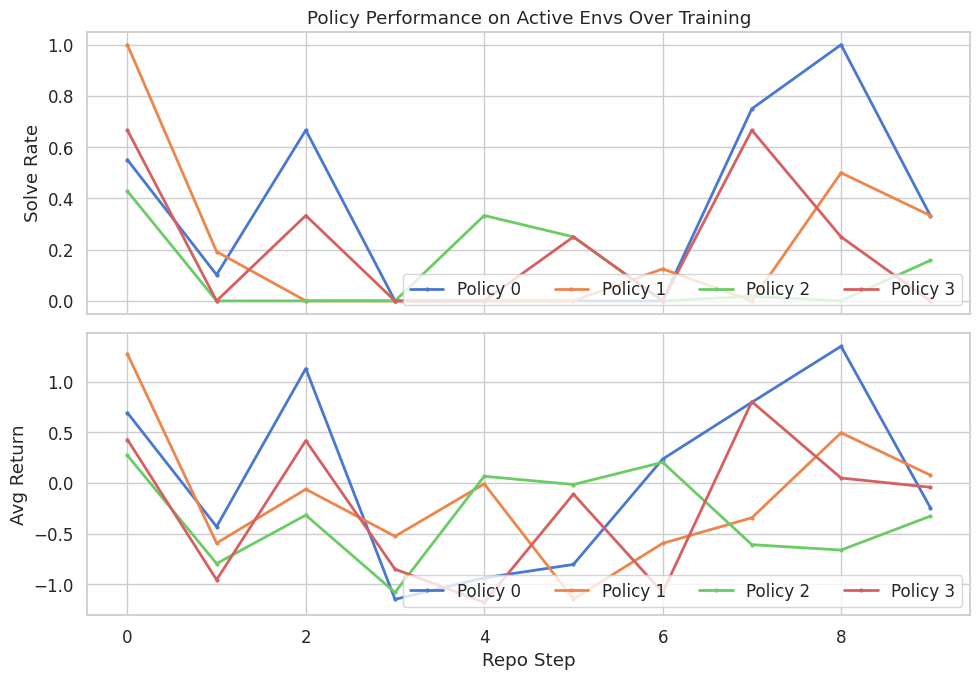

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
steps = np.arange(T)
colors = sns.color_palette("muted", P)

# Top: solve rate
for p in range(P):
    ax1.plot(steps, mean_solve_rate[:, p], color=colors[p], lw=2,
             label=f"Policy {p}", marker='.', markersize=4)
ax1.set_ylabel("Solve Rate")
ax1.set_title("Policy Performance on Active Envs Over Training")
ax1.legend(ncol=P, loc='lower right')
ax1.set_ylim(-0.05, 1.05)

# Bottom: avg return
for p in range(P):
    ax2.plot(steps, mean_avg_return[:, p], color=colors[p], lw=2,
             label=f"Policy {p}", marker='.', markersize=4)
ax2.set_ylabel("Avg Return")
ax2.set_xlabel("Repo Step")
ax2.legend(ncol=P, loc='lower right')

plt.tight_layout()
plt.show()


## Plot 2: Active Envs Per Policy

Number of environments assigned to each policy at each repo step.


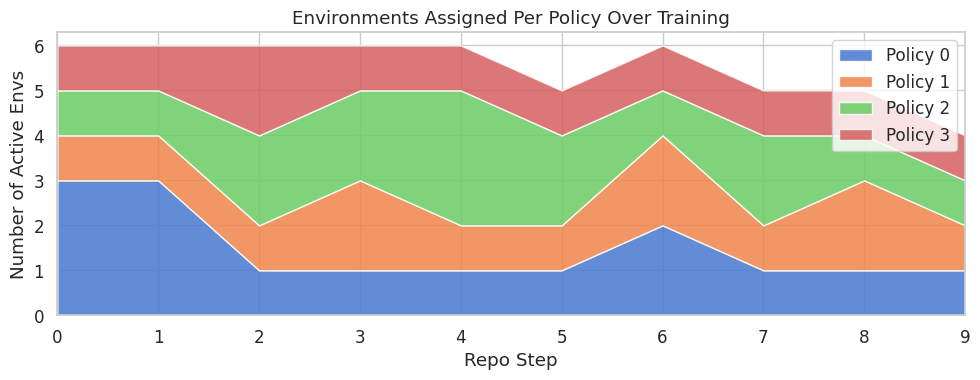

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))

colors = sns.color_palette("muted", P)
steps = np.arange(T)

# Stacked area showing each policy's share of active envs
ax.stackplot(steps, n_active_envs.T, labels=[f"Policy {p}" for p in range(P)],
             colors=colors, alpha=0.85)
ax.set_xlabel("Repo Step")
ax.set_ylabel("Number of Active Envs")
ax.set_title("Environments Assigned Per Policy Over Training")
ax.legend(loc='upper right')
ax.set_xlim(0, T - 1)

plt.tight_layout()
plt.show()


## Plot 3: Mean Per-Environment Entropy

For each candidate environment $e$, the column $a_{:,e}$ is a distribution over policies.
Entropy $H(e) = -\sum_p a_{p,e} \log a_{p,e}$ measures how decisive the policies are about that environment.
Low entropy = clear winner; high entropy = ambiguity. Plot shows the mean ± std across candidate envs per step.


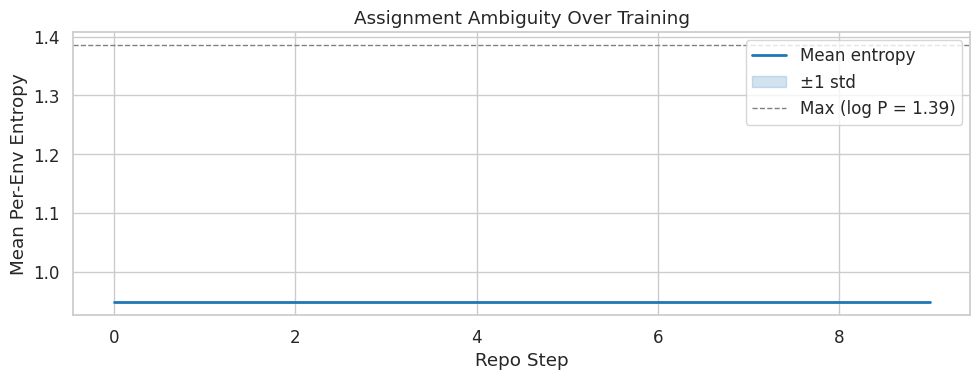

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))

max_entropy = np.log(P)  # theoretical maximum if all policies equal

steps = np.arange(T)
ax.plot(steps, mean_env_entropy, color='tab:blue', lw=2, label="Mean entropy")
ax.fill_between(steps, mean_env_entropy - std_env_entropy,
                mean_env_entropy + std_env_entropy, alpha=0.2, color='tab:blue',
                label="±1 std")
ax.axhline(max_entropy, color='gray', ls='--', lw=1,
           label=f"Max (log P = {max_entropy:.2f})")
ax.set_xlabel("Repo Step")
ax.set_ylabel("Mean Per-Env Entropy")
ax.set_title("Assignment Ambiguity Over Training")
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


## Plot 4: Solve Rate by Affinity Quantile Over Time

At each step, all (policy, env) pairs are split into affinity quintiles. Lines show the mean solve rate for each bin.
If the affinity scoring is meaningful, high-affinity bins should have higher solve rates, and the gap should grow as training progresses.


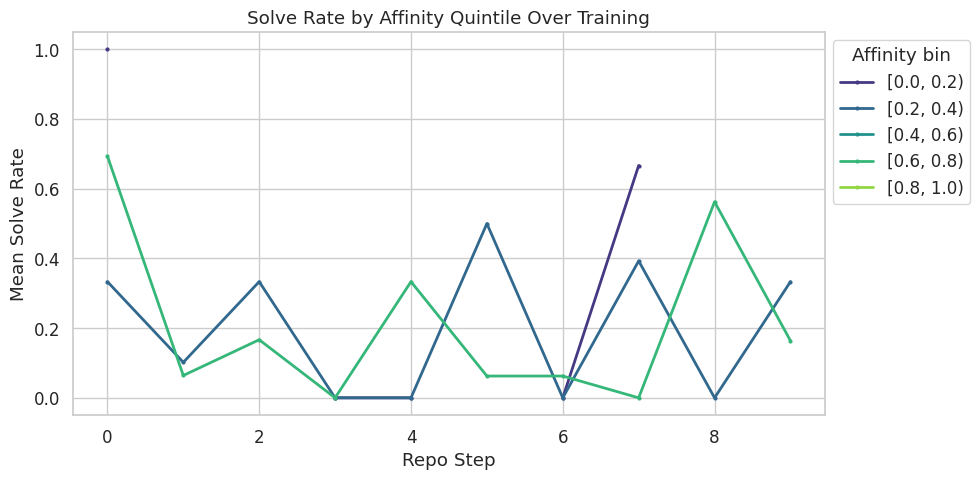

In [ ]:
# Bin affinity scores into quintiles and compute mean solve rate per bin per step
n_bins = 5
bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
binned_solve_rate = np.full((T, n_bins), np.nan)
bin_labels = [f"[{bin_edges[i]:.1f}, {bin_edges[i+1]:.1f})" for i in range(n_bins)]

for t in range(T):
    aff_flat = affinities[t].ravel()
    sr_flat  = solve_rates[t].ravel()
    valid = ~np.isnan(sr_flat)
    if valid.any():
        aff_v = aff_flat[valid]
        sr_v  = sr_flat[valid]
        for b in range(n_bins):
            lo, hi = bin_edges[b], bin_edges[b + 1]
            if b == n_bins - 1:
                in_bin = (aff_v >= lo) & (aff_v <= hi)
            else:
                in_bin = (aff_v >= lo) & (aff_v < hi)
            if in_bin.sum() > 0:
                binned_solve_rate[t, b] = sr_v[in_bin].mean()

fig, ax = plt.subplots(1, 1, figsize=(10, 5))

steps = np.arange(T)
palette = sns.color_palette("viridis", n_bins)

for b in range(n_bins):
    ax.plot(steps, binned_solve_rate[:, b], color=palette[b], lw=2,
            label=bin_labels[b], marker='.', markersize=4)

ax.set_xlabel("Repo Step")
ax.set_ylabel("Mean Solve Rate")
ax.set_title("Solve Rate by Affinity Quintile Over Training")
ax.legend(title="Affinity bin", loc='upper left', bbox_to_anchor=(1, 1))
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()


## Plot 5: Affinity–Performance Spearman Correlation Over Time

Spearman rank correlation $\rho$ between flattened affinity scores and solve rates at each step.
This measures whether the affinity scoring function is becoming better at predicting actual policy performance.


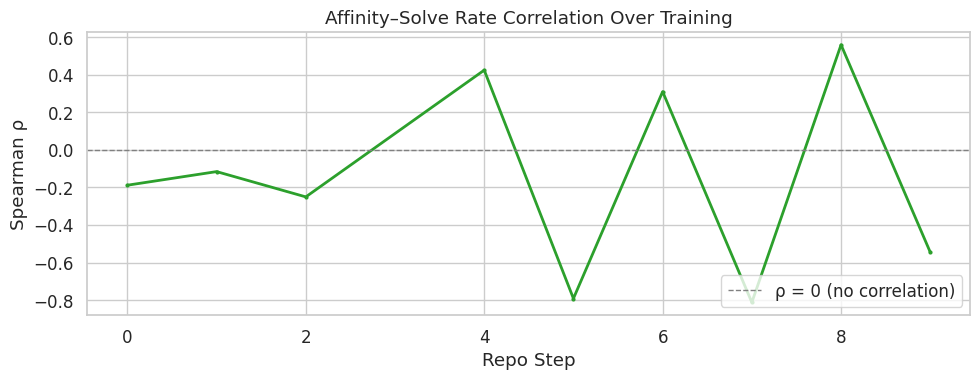

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))

steps = np.arange(T)
valid = ~np.isnan(spearman_rhos)
ax.plot(steps[valid], spearman_rhos[valid], color='tab:green', lw=2, marker='.', markersize=4)
ax.axhline(0, color='gray', ls='--', lw=1, label="ρ = 0 (no correlation)")
ax.set_xlabel("Repo Step")
ax.set_ylabel("Spearman ρ")
ax.set_title("Affinity–Solve Rate Correlation Over Training")
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()
